# Figure 4 Single-Compound Modality Jump Plot (f/h style)

This notebook reproduces the Figure 4f/h style grouped MoA bar plot for one compound (e.g., JH27 or JH32), extended to three modality levels (two jumps).


In [53]:
from __future__ import annotations

import glob
import math
import pickle
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve repo root
HERE = Path.cwd().resolve()
if (HERE / 'Data').exists() and (HERE / 'notebooks').exists():
    REPO_ROOT = HERE
elif (HERE.parent / 'Data').exists() and (HERE.parent / 'notebooks').exists():
    REPO_ROOT = HERE.parent
elif (HERE / 'code_repository' / 'Data').exists():
    REPO_ROOT = HERE / 'code_repository'
elif (HERE.parent / 'code_repository' / 'Data').exists():
    REPO_ROOT = HERE.parent / 'code_repository'
else:
    REPO_ROOT = HERE

for p in [REPO_ROOT / 'notebooks', REPO_ROOT / 'scripts']:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

from analysis.plot_style import apply_style, save_figure, set_save_dir

FIG_DIR = set_save_dir(REPO_ROOT, 'figure4')
apply_style()

OUT_DIR = REPO_ROOT / 'analysis_exports' / 'figure4_novelty_modality_jumps'
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('REPO_ROOT:', REPO_ROOT)
print('FIG_DIR   :', FIG_DIR)
print('OUT_DIR   :', OUT_DIR)


REPO_ROOT: /mnt/nas/PhD/Code/Ms_paint/code_repository
FIG_DIR   : /mnt/nas/PhD/Code/Ms_paint/code_repository/images/figure4
OUT_DIR   : /mnt/nas/PhD/Code/Ms_paint/code_repository/analysis_exports/figure4_novelty_modality_jumps


In [54]:
# ---- Config ----
COMPOUND_ID = 'JH27'                       # e.g. JH27 or JH32
SPLIT_TASK = 'binary_loo_ablation'         # 'binary_loo_ablation' or 'binary_loso_ablation'

# Optional overrides if needed
RUN_DIR_OVERRIDE = {
    'ecfp_cp': None,
    'ecfp_cp_prot': None,
    'all_modalities': None,
}

RUN_SPECS = {
    'ecfp_cp': {
        'label': 'ECFP+CP',
        'exp': 'Uncertainty_experiment_semantic_ecfp_cp',
        'run': 'semantic_BioBERT_tabm_Text_Embedding+ECFP+CellPaint',
    },
    'ecfp_cp_prot': {
        'label': '+Proteomics',
        'exp': 'Uncertainty_experiment_semantic_prot_ecfp_cp',
        'run': 'semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint',
    },
    'all_modalities': {
        'label': '+MIC+GC (all)',
        'exp': 'Uncertainty_experiment_semantic',
        'run': 'semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC',
    },
}

DISPLAY_ORDER = [
    'Fatty acid','Nitrofurans','Folic acid','Membrane',
    'RNA synth.','LPS synth.','DNA repl.','Cell wall','Protein syn.'
]
COLORS = ['#264653','#287271','#2a9d8f','#8ab17d','#e9c46a','#efb366','#f4a261','#ee8959','#e76f51']

CANON_MAP = {
    'Fatty acid': ['Fatty acid', 'Fatty acid synthesis'],
    'Nitrofurans': ['Nitrofurans'],
    'Folic acid': ['Folic acid', 'Folic acid metabolism', 'Folic acid biosynthesis'],
    'Membrane': ['Membrane', 'Membrane disruption', 'Membrane integrity'],
    'RNA synth.': ['RNA synth.', 'RNA Synthesis', 'RNA synthesis'],
    'LPS synth.': ['LPS synth.', 'lipopolysaccharide synthesis', 'LPS synthesis'],
    'DNA repl.': ['DNA repl.', 'DNA replication', 'DNA Replication'],
    'Cell wall': ['Cell wall', 'Cell wall biosynthesis', 'Cell-wall biosynthesis'],
    'Protein syn.': ['Protein syn.', 'Protein synthesis', 'Protein Synthesis'],
}
SYN_TO_DISPLAY = {syn.lower(): disp for disp, syns in CANON_MAP.items() for syn in syns}

def map_to_display(m):
    if m is None:
        return None
    return SYN_TO_DISPLAY.get(str(m).strip().lower())


def resolve_run_dir(key: str) -> Path:
    ov = RUN_DIR_OVERRIDE.get(key)
    if ov:
        return Path(ov)
    spec = RUN_SPECS[key]
    return REPO_ROOT / 'predictions' / spec['exp'] / SPLIT_TASK / spec['run']

RUN_DIRS = {k: resolve_run_dir(k) for k in RUN_SPECS}
for k, rp in RUN_DIRS.items():
    print(f'{k:16s} -> {rp}')

missing = [k for k, rp in RUN_DIRS.items() if not rp.exists()]
if missing:
    raise FileNotFoundError(f'Missing run dirs for: {missing}')


ecfp_cp          -> /mnt/nas/PhD/Code/Ms_paint/code_repository/predictions/Uncertainty_experiment_semantic_ecfp_cp/binary_loo_ablation/semantic_BioBERT_tabm_Text_Embedding+ECFP+CellPaint
ecfp_cp_prot     -> /mnt/nas/PhD/Code/Ms_paint/code_repository/predictions/Uncertainty_experiment_semantic_prot_ecfp_cp/binary_loo_ablation/semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint
all_modalities   -> /mnt/nas/PhD/Code/Ms_paint/code_repository/predictions/Uncertainty_experiment_semantic/binary_loo_ablation/semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC


In [55]:
# ---- Helpers ----
def load_all_pickles(run_dir: Path) -> pd.DataFrame:
    files = sorted(run_dir.glob('fold*_rep*_seed*.pkl'))
    if not files:
        raise FileNotFoundError(f'No fold PKLs in {run_dir}')
    dfs = []
    for fp in files:
        try:
            dfs.append(pd.read_pickle(fp))
        except Exception as e:
            print(f'Skipping {fp}: {e}')
    if not dfs:
        raise RuntimeError(f'Loaded 0 DataFrames from {run_dir}')
    df = pd.concat(dfs, axis=0, ignore_index=False)
    if 'SampleID' not in df.columns:
        if df.index.name == 'SampleID':
            df = df.reset_index()
        else:
            raise ValueError('No SampleID in prediction frames.')
    return df


def replicate_values_by_moa(df: pd.DataFrame, compound_id: str) -> dict[str, np.ndarray]:
    vals: dict[str, list[np.ndarray]] = {}
    msk = df['SampleID'].astype(str).str.startswith(str(compound_id) + '_')

    if ('CandidateMoA' in df.columns) and ('ProbaPos' in df.columns):
        sub = df.loc[msk, ['CandidateMoA', 'ProbaPos']].dropna()
        for moa, arr in sub.groupby('CandidateMoA')['ProbaPos']:
            disp = map_to_display(moa)
            if disp is None:
                continue
            vals.setdefault(disp, []).append(arr.to_numpy(dtype=float))
    else:
        prob_cols = [c for c in df.columns if c.startswith('proba_')]
        if not prob_cols:
            raise ValueError('No pairwise (CandidateMoA/ProbaPos) or multiclass proba columns found.')
        sub = (
            df.loc[msk, ['SampleID'] + prob_cols]
              .melt(id_vars='SampleID', var_name='MoA', value_name='Proba')
              .dropna()
        )
        sub['MoA'] = sub['MoA'].str.replace('^proba_', '', regex=True)
        for moa, arr in sub.groupby('MoA')['Proba']:
            disp = map_to_display(moa)
            if disp is None:
                continue
            vals.setdefault(disp, []).append(arr.to_numpy(dtype=float))

    out = {}
    for k in vals:
        out[k] = np.concatenate(vals[k], axis=0) if vals[k] else np.array([], dtype=float)
    return out


def summarize(vals_dict: dict[str, np.ndarray], order: list[str]) -> pd.DataFrame:
    rows = []
    for moa in order:
        arr = vals_dict.get(moa, np.array([], dtype=float))
        if arr.size == 0:
            rows.append({'MoA': moa, 'n': 0, 'mean': np.nan, 'std': np.nan, 'sem': np.nan})
        else:
            std = float(np.std(arr, ddof=1)) if arr.size > 1 else 0.0
            rows.append({
                'MoA': moa,
                'n': int(arr.size),
                'mean': float(np.mean(arr)),
                'std': std,
                'sem': float(std / np.sqrt(arr.size)) if arr.size > 1 else 0.0,
            })
    return pd.DataFrame(rows)


def true_moa_for_compound(compound_id: str) -> str | None:
    with open(REPO_ROOT / 'Data' / 'Base' / 'y_labels.pkl', 'rb') as f:
        y = pickle.load(f)
    if isinstance(y, dict):
        y = pd.Series(y)
    else:
        y = pd.Series(y)
    y.index = y.index.astype(str)
    match = y[y.index.str.startswith(str(compound_id) + '_')]
    if len(match) == 0:
        return None
    return map_to_display(match.iloc[0])

# ---- Aggregate all three runs ----
summaries = {}
for key in ['ecfp_cp', 'ecfp_cp_prot', 'all_modalities']:
    df = load_all_pickles(RUN_DIRS[key])
    vals = replicate_values_by_moa(df, COMPOUND_ID)
    summaries[key] = summarize(vals, DISPLAY_ORDER)

true_moa_disp = true_moa_for_compound(COMPOUND_ID)
true_idx = DISPLAY_ORDER.index(true_moa_disp) if true_moa_disp in DISPLAY_ORDER else None

print('COMPOUND_ID   :', COMPOUND_ID)
print('SPLIT_TASK    :', SPLIT_TASK)
print('True MoA      :', true_moa_disp)
for key in summaries:
    print(key, 'n by MoA total =', int(np.nansum(summaries[key]['n'].values)))

# Save numeric table for SI
stack_rows = []
for key, sdf in summaries.items():
    tmp = sdf.copy()
    tmp['ConfigKey'] = key
    tmp['Config'] = RUN_SPECS[key]['label']
    tmp['CompoundID'] = COMPOUND_ID
    tmp['SplitTask'] = SPLIT_TASK
    stack_rows.append(tmp)

stack_df = pd.concat(stack_rows, ignore_index=True)
stack_df.to_csv(OUT_DIR / f'{COMPOUND_ID}_{SPLIT_TASK}_moa_grouped_stats.csv', index=False)
print('Saved:', OUT_DIR / f'{COMPOUND_ID}_{SPLIT_TASK}_moa_grouped_stats.csv')
stack_df.head()


COMPOUND_ID   : JH27
SPLIT_TASK    : binary_loo_ablation
True MoA      : DNA repl.
ecfp_cp n by MoA total = 1800
ecfp_cp_prot n by MoA total = 1800
all_modalities n by MoA total = 1800
Saved: /mnt/nas/PhD/Code/Ms_paint/code_repository/analysis_exports/figure4_novelty_modality_jumps/JH27_binary_loo_ablation_moa_grouped_stats.csv


,MoA,n,mean,std,sem,ConfigKey,Config,CompoundID,SplitTask
0,Fatty acid,200,2.003925e-05,3.762076e-05,2.660190e-06,ecfp_cp,ECFP+CP,JH27,binary_loo_ablation
1,Nitrofurans,200,1.317120e-05,2.532164e-05,1.790510e-06,ecfp_cp,ECFP+CP,JH27,binary_loo_ablation
2,Folic acid,200,1.603366e-06,2.162145e-06,1.528868e-07,ecfp_cp,ECFP+CP,JH27,binary_loo_ablation
3,Membrane,200,3.548063e-07,5.831252e-07,4.123318e-08,ecfp_cp,ECFP+CP,JH27,binary_loo_ablation
4,RNA synth.,200,9.401244e-06,1.143484e-05,8.085650e-07,ecfp_cp,ECFP+CP,JH27,binary_loo_ablation


Saved figure: /mnt/nas/PhD/Code/Ms_paint/code_repository/images/figure4/figure4_JH27_binary_loo_ablation_modality_two_jumps.png


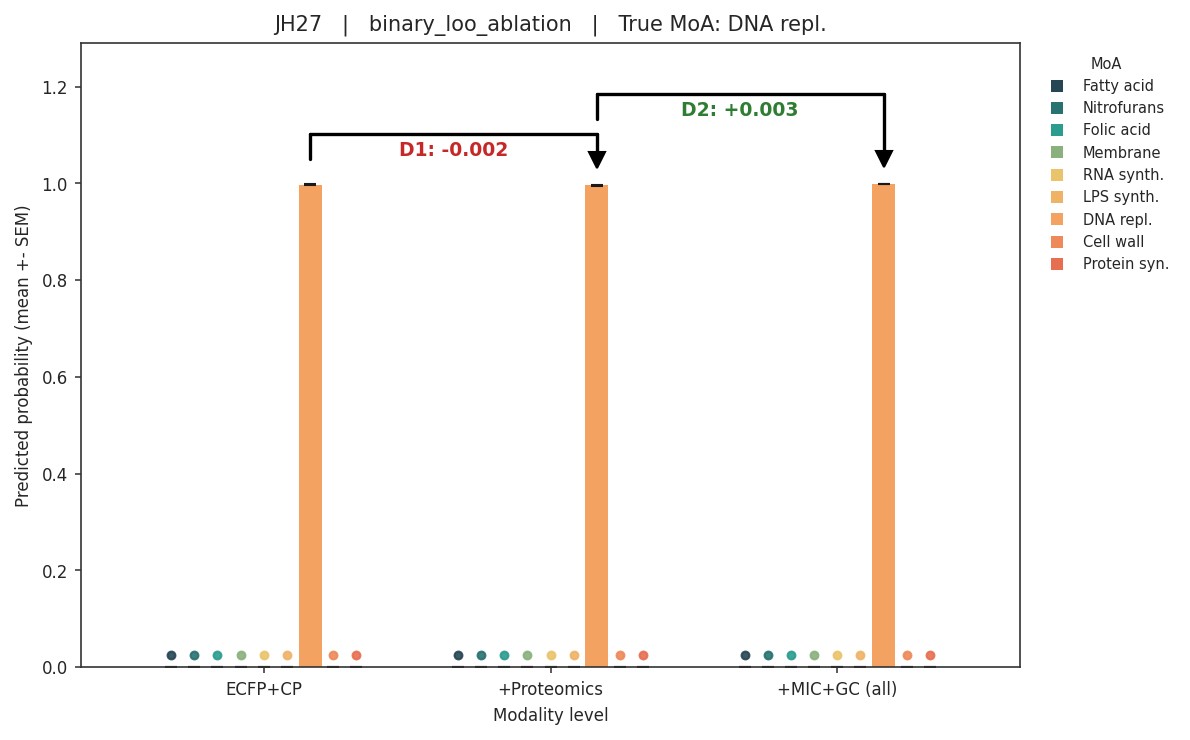

In [ ]:
# ---- Plot (Figure 4f/h style, 3 groups with 2 jumps) ----
color_map = {moa: COLORS[i % len(COLORS)] for i, moa in enumerate(DISPLAY_ORDER)}

def _compound_name(cid: str) -> str:
    xlsx = REPO_ROOT / 'Data' / 'Compound_data' / '250808_compounds.xlsx'
    if not xlsx.exists():
        return cid
    try:
        sdf = pd.read_excel(xlsx)
        if 'NameID' in sdf.columns and 'Compound Name' in sdf.columns:
            m = sdf.loc[sdf['NameID'].astype(str) == str(cid), 'Compound Name']
            if len(m) > 0 and pd.notna(m.iloc[0]):
                return str(m.iloc[0])
    except Exception:
        pass
    return cid

compound_name = _compound_name(COMPOUND_ID)

fig, ax = plt.subplots(figsize=(8.0, 5.0))

group_keys = ['ecfp_cp', 'ecfp_cp_prot', 'all_modalities']
group_labels = [RUN_SPECS[k]['label'] for k in group_keys]
group_centers = np.array([0.0, 0.55, 1.10])
K = len(DISPLAY_ORDER)
group_width = 0.40
bar_width = group_width / K
offsets = (-group_width / 2) + (np.arange(K) + 0.5) * bar_width

for gi, key in enumerate(group_keys):
    s = summaries[key]
    x = group_centers[gi] + offsets
    ax.bar(
        x,
        s['mean'].values,
        yerr=s['sem'].values,
        capsize=3,
        width=bar_width,
        color=[color_map[m] for m in DISPLAY_ORDER],
        edgecolor='none',
        zorder=2,
    )

# Floor dots
floor = 0.025
dot_size = 14
for gi, key in enumerate(group_keys):
    x = group_centers[gi] + offsets
    for j, moa in enumerate(DISPLAY_ORDER):
        mu = summaries[key].loc[j, 'mean']
        if np.isfinite(mu):
            ydot = floor * (1.00 + 0.02 * gi)
            ax.plot([x[j]], [ydot], marker='o', color=color_map[moa], alpha=0.9, markersize=math.sqrt(dot_size), zorder=4)

# Two jump connectors
if true_idx is not None:
    x_true = [float(group_centers[g] + offsets[true_idx]) for g in range(3)]

    means = [
        float(summaries['ecfp_cp'].loc[true_idx, 'mean']),
        float(summaries['ecfp_cp_prot'].loc[true_idx, 'mean']),
        float(summaries['all_modalities'].loc[true_idx, 'mean']),
    ]
    sems = [
        float(summaries['ecfp_cp'].loc[true_idx, 'sem']),
        float(summaries['ecfp_cp_prot'].loc[true_idx, 'sem']),
        float(summaries['all_modalities'].loc[true_idx, 'sem']),
    ]
    tops = [m + s for m, s in zip(means, sems)]

    ymin, ymax = ax.get_ylim()
    yspan = max(1e-6, ymax - ymin)
    hover_pad = 0.050 * yspan
    min_stem = 0.050 * yspan
    extra_head = 0.10 * yspan
    text_drop = 0.014 * yspan
    min_base = floor + 0.020

    def draw_jump(i_left: int, i_right: int, label: str, level_boost: float = 0.0, left_base_lift: float = 0.0):
        xl, xr = x_true[i_left], x_true[i_right]
        y_left_base = max(tops[i_left] + hover_pad, min_base) + left_base_lift
        y_right_base = tops[i_right] + hover_pad
        y_h = max(y_left_base, y_right_base) + min_stem + level_boost

        ax.plot([xl, xl], [y_left_base, y_h], color='black', lw=1.6, zorder=6)
        ax.plot([xl, xr], [y_h, y_h], color='black', lw=1.6, zorder=6)
        ax.plot([xr, xr], [y_h, y_right_base], color='black', lw=1.6, zorder=6)
        ax.plot(
            [xr], [y_right_base],
            marker='v', markersize=7.5,
            color='black', markeredgecolor='black',
            zorder=7, clip_on=False,
        )

        delta = means[i_right] - means[i_left]
        delta_txt = f"{label}: {'+' if delta >= 0 else '-'}{abs(delta):.3f}"
        ax.text(
            (xl + xr) / 2,
            y_h - text_drop,
            delta_txt,
            ha='center',
            va='top',
            fontsize=9,
            fontweight='bold',
            color=('#2e7d32' if delta >= 0 else '#c62828'),
            zorder=7,
        )
        return y_h + extra_head

    top1 = draw_jump(0, 1, 'D1', level_boost=0.0, left_base_lift=0.0)
    top2 = draw_jump(1, 2, 'D2', level_boost=0.00 * yspan, left_base_lift=0.08 * yspan)
    need_top = max(top1, top2)
    if need_top > ymax:
        ax.set_ylim(ymin, need_top)

ax.set_xticks(group_centers)
ax.set_xticklabels(group_labels)
ax.set_xlim(group_centers[0] - 0.35, group_centers[2] + 0.35)
ax.set_ylabel('Predicted probability (mean +- SEM)')
ax.set_xlabel('Modality level')
ax.set_ylim(0, max(ax.get_ylim()[1], 1.0))
ax.set_title(f'{compound_name}   |   {SPLIT_TASK}' + (f'   |   True MoA: {true_moa_disp}' if true_moa_disp else ''))

for spine in ['left', 'bottom', 'top', 'right']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.2)
    ax.spines[spine].set_color('black')

handles = [
    plt.Line2D([0], [0], marker='s', linestyle='', color='none', markerfacecolor=color_map[m], markeredgecolor='none', markersize=6, label=m)
    for m in DISPLAY_ORDER
]
ax.legend(handles=handles, title='MoA', frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1.0))

ax.grid(visible=False)
plt.tight_layout()

save_name = f'figure4_{COMPOUND_ID}_{SPLIT_TASK}_modality_two_jumps'
save_figure(fig, save_name)
print('Saved figure:', FIG_DIR / (save_name + '.png'))
plt.show()

